# Тема 3. Крупные универсальные базы знаний

In [1]:
%pip install rdflib -q

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.error import URLError, HTTPError
from urllib.parse import quote
import json, html, re

from IPython.display import display, HTML
from rdflib import Graph, Namespace, URIRef, Literal
from rdflib.namespace import RDF, RDFS, XSD

WD = Namespace("http://www.wikidata.org/entity/")
WDT = Namespace("http://www.wikidata.org/prop/direct/")
P = Namespace("http://www.wikidata.org/prop/")
PS = Namespace("http://www.wikidata.org/prop/statement/")
PQ = Namespace("http://www.wikidata.org/prop/qualifier/")
PR = Namespace("http://www.wikidata.org/prop/reference/")
WIKIBASE = Namespace("http://wikiba.se/ontology#")
PROV = Namespace("http://www.w3.org/ns/prov#")
SCHEMA = Namespace("https://schema.org/")
GEO = Namespace("http://www.opengis.net/ont/geosparql#")

PREFIXES = """
PREFIX wd: <http://www.wikidata.org/entity/>
PREFIX wdt: <http://www.wikidata.org/prop/direct/>
PREFIX p: <http://www.wikidata.org/prop/>
PREFIX ps: <http://www.wikidata.org/prop/statement/>
PREFIX pq: <http://www.wikidata.org/prop/qualifier/>
PREFIX pr: <http://www.wikidata.org/prop/reference/>
PREFIX wikibase: <http://wikiba.se/ontology#>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX bd: <http://www.bigdata.com/rdf#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
"""

def show_table(rows, columns=None):
    if not rows:
        display(HTML('<i>Нет данных для вывода.</i>'))
        return
    columns = columns or list(rows[0].keys())
    head = ''.join(f'<th style="padding:6px;border:1px solid #bbb;background:#eef3f7">{html.escape(str(c))}</th>' for c in columns)
    body = []
    for row in rows:
        cells = ''.join(f'<td style="padding:6px;border:1px solid #ccc;vertical-align:top">{html.escape(str(row.get(c,"")))}</td>' for c in columns)
        body.append(f'<tr>{cells}</tr>')
    display(HTML('<table style="border-collapse:collapse;width:100%"><thead><tr>'+head+'</tr></thead><tbody>'+''.join(body)+'</tbody></table>'))


# От локального RDF-графа к универсальной базе знаний

**Крупная универсальная база знаний** — это база знаний, которая охватывает множество предметных областей и связывает большое число сущностей общими идентификаторами, отношениями, внешними каталогами и сведениями о происхождении фактов. В отличие от небольшого учебного RDF-графа, такой ресурс формируется множеством участников и объединяет разные практики моделирования, языки и исторические значения, поэтому работа с ним требует не только чтения троек, но и проверки контекста каждого факта.

Главное преимущество крупной универсальной базы знаний состоит не просто в размере, а в том, что одна сущность может быть связана с другими сущностями, энциклопедическими статьями, каталогами и внешними наборами данных, благодаря чему её можно анализировать сразу в нескольких представлениях.


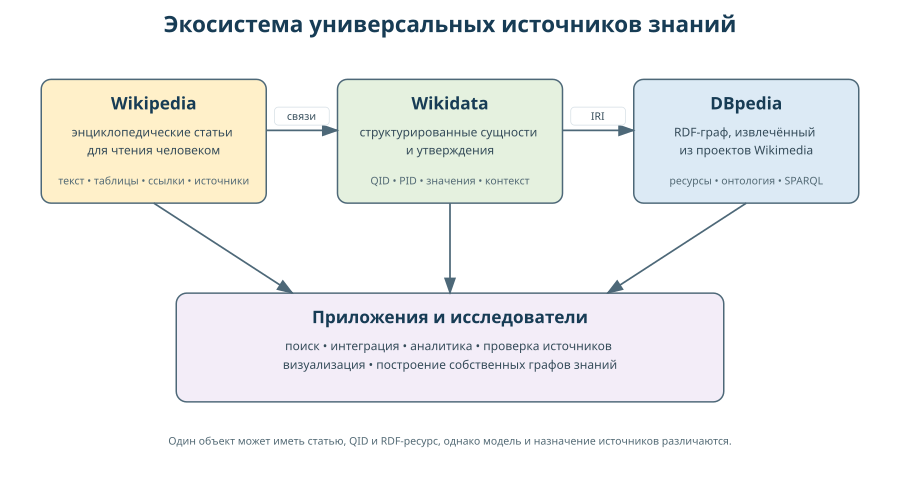

In [3]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="900" height="500" viewBox="0 0 1200 665">
  <rect width="1200" height="665" fill="white"/>
  <defs>
    <marker id="ecoArrow" markerWidth="11" markerHeight="11" refX="9" refY="3.5" orient="auto">
      <path d="M0,0 L0,7 L10,3.5 z" fill="#4d6878"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#4d6878;stroke-width:2}
    .title{font:700 23px sans-serif;fill:#173c55;text-anchor:middle}
    .body{font:16px sans-serif;fill:#344b59;text-anchor:middle}
    .small{font:14px sans-serif;fill:#526974;text-anchor:middle}
    .head{font:700 30px sans-serif;fill:#173c55;text-anchor:middle}
    .edge{stroke:#4d6878;stroke-width:2.3;fill:none;marker-end:url(#ecoArrow)}
    .label{font:14px sans-serif;fill:#344b59;text-anchor:middle}
    .labelBg{fill:white;stroke:#d7e0e6;stroke-width:1}
  </style>

  <text x="600" y="42" class="head">Экосистема универсальных источников знаний</text>

  <rect x="55" y="105" width="300" height="165" rx="13" fill="#fff0c9" class="box"/>
  <text x="205" y="145" class="title">Wikipedia</text>
  <text x="205" y="181" class="body">
    <tspan x="205" dy="0">энциклопедические статьи</tspan>
    <tspan x="205" dy="24">для чтения человеком</tspan>
  </text>
  <text x="205" y="245" class="small">текст • таблицы • ссылки • источники</text>

  <rect x="450" y="105" width="300" height="165" rx="13" fill="#e5f1df" class="box"/>
  <text x="600" y="145" class="title">Wikidata</text>
  <text x="600" y="181" class="body">
    <tspan x="600" dy="0">структурированные сущности</tspan>
    <tspan x="600" dy="24">и утверждения</tspan>
  </text>
  <text x="600" y="245" class="small">QID • PID • значения • контекст</text>

  <rect x="845" y="105" width="300" height="165" rx="13" fill="#dceaf5" class="box"/>
  <text x="995" y="145" class="title">DBpedia</text>
  <text x="995" y="181" class="body">
    <tspan x="995" dy="0">RDF-граф, извлечённый</tspan>
    <tspan x="995" dy="24">из проектов Wikimedia</tspan>
  </text>
  <text x="995" y="245" class="small">ресурсы • онтология • SPARQL</text>

  <!-- arrows begin/end on box borders -->
  <line x1="355" y1="173" x2="450" y2="173" class="edge"/>
  <rect x="366" y="142" width="73" height="24" rx="5" class="labelBg"/>
  <text x="402" y="159" class="label">связи</text>

  <line x1="750" y1="173" x2="845" y2="173" class="edge"/>
  <rect x="761" y="142" width="73" height="24" rx="5" class="labelBg"/>
  <text x="797" y="159" class="label">IRI</text>

  <rect x="235" y="390" width="730" height="145" rx="14" fill="#f3edf8" class="box"/>
  <text x="600" y="430" class="title">Приложения и исследователи</text>
  <text x="600" y="466" class="body">
    <tspan x="600" dy="0">поиск • интеграция • аналитика • проверка источников</tspan>
    <tspan x="600" dy="25">визуализация • построение собственных графов знаний</tspan>
  </text>

  <line x1="205" y1="270" x2="390" y2="390" class="edge"/>
  <line x1="600" y1="270" x2="600" y2="390" class="edge"/>
  <line x1="995" y1="270" x2="810" y2="390" class="edge"/>

  <text x="600" y="592" class="small">
    Один объект может иметь статью, QID и RDF-ресурс, однако модель и назначение источников различаются.
  </text>
</svg>
"""

display(SVG(svg))


### Формальная рамка

Универсальную базу знаний удобно рассматривать как **размеченный ориентированный мультиграф**, то есть граф, в котором рёбра имеют направление, между одной и той же парой вершин могут существовать несколько разных рёбер, а вершины и рёбра снабжаются типами или метками:

$$
KG=\langle V,E,\lambda_V,\lambda_E,\mu\rangle,
$$

где $V$ обозначает множество сущностей и служебных узлов, $E$ задаёт множество ориентированных рёбер, функции $\lambda_V$ и $\lambda_E$ задают типы и метки вершин и рёбер, а $\mu$ хранит дополнительные атрибуты, включая языковые метки, временной контекст и сведения о происхождении факта.

В RDF тот же граф представляется множеством троек

$$
G_{RDF}\subseteq (I\cup B)\times I\times(I\cup B\cup L),
$$

где $I$ является множеством IRI, $B$ обозначает пустые узлы (`blank nodes`), а $L$ обозначает литералы (`literals`).

Для анализа базы знаний полезно также различать фактические данные, схему и происхождение:

$$
KB=D\cup S\cup P,
$$

где $D$ содержит фактические данные, $S$ задаёт схему или систему понятий, а $P$ хранит сведения о происхождении и контексте.


# Wikipedia как энциклопедический источник

Wikipedia организована вокруг статей, в которых смысл выражается связным текстом, разделами, таблицами, ссылками, шаблонами и категориями, поэтому она хорошо передаёт причины, контекст и неоднозначные формулировки, однако автоматическое извлечение единообразных фактов осложняется тем, что одинаковый смысл может быть записан разными словами и в разных частях страницы.

Важным структурным элементом статьи является **инфобокс (infobox)**, то есть компактная таблица с типовыми полями об объекте. Именно такие структурированные части страниц используются DBpedia как один из источников для извлечения RDF-данных.

Поскольку название статьи не является глобальным идентификатором сущности и может различаться между языковыми разделами, для надёжного машинного сопоставления требуется отдельный устойчивый идентификатор, который в Wikidata задаётся на уровне элемента и рассматривается далее.

После того как роль Wikipedia как текстового источника определена, можно перейти к Wikidata, где тот же объект описывается уже не абзацами текста, а системой идентификаторов, свойств и утверждений.

# Wikidata как база структурированных утверждений

Wikidata работает на программной платформе **Wikibase**, то есть системе для создания и ведения совместно редактируемых баз структурированных знаний, в которой задаются типы сущностей, свойства и модель утверждений.

Основные типы сущностей Wikidata:

- **элемент (item)** представляет объект, понятие или тему и имеет идентификатор вида `Q...`,
- **свойство (property)** задаёт тип отношения или характеристики и имеет идентификатор вида `P...`,
- **лексема (lexeme)** представляет лексикографическую единицу и имеет идентификатор вида `L...`, 
- **схема сущности (EntitySchema)** описывает ожидаемую структуру данных и имеет идентификатор вида `E...`.

**Идентификатор элемента Wikidata (QID)** — это устойчивый идентификатор элемента, начинающийся с буквы `Q`, например `Q649`, причём он не зависит от языка и не заменяется при обычном переименовании элемента.

Элемент содержит:
- **метку (label)** - короткое человекочитаемое имя на определённом языке;
- **описание (description)**, - краткую фразу для различения одноимённых элементов;
- **псевдонимы (aliases)** - альтернативные названия и варианты написания;
- **утверждения (statements)** - структурированные записи о свойствах сущности и их значениях;
- **ссылки на страницы проектов Wikimedia (sitelinks)**, которые связывают элемент со статьями Wikipedia и страницами других проектов Wikimedia;
- **внешние идентификаторы (external identifiers)**-  коды той же сущности во внешних каталогах и информационных системах.


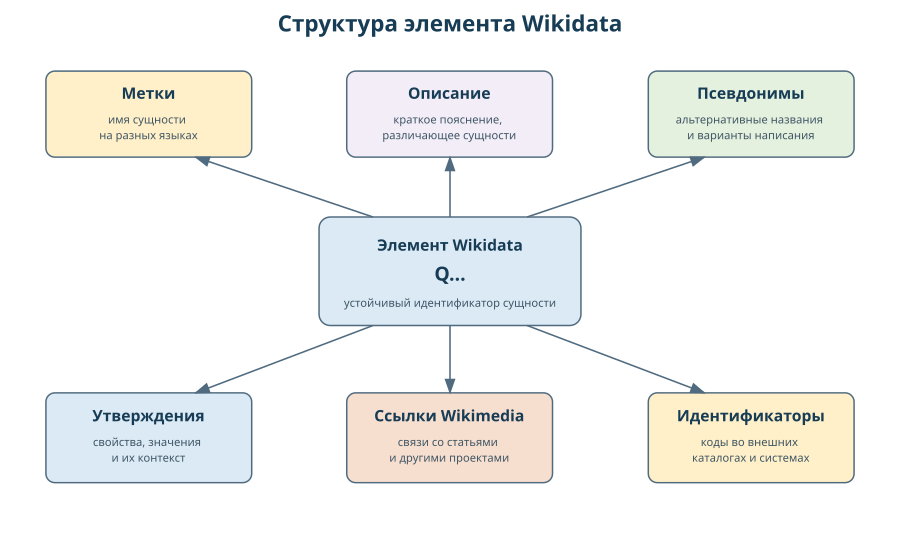

In [4]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="900" height="550" viewBox="0 0 1200 735">
  <rect width="1200" height="735" fill="white"/>
  <defs>
    <marker id="itemArrow" markerWidth="11" markerHeight="11" refX="9" refY="3.5" orient="auto">
      <path d="M0,0 L0,7 L10,3.5 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#506b7f;stroke-width:2}
    .title{font:700 21px sans-serif;fill:#173c55;text-anchor:middle}
    .body{font:15px sans-serif;fill:#3e5563;text-anchor:middle}
    .head{font:700 30px sans-serif;fill:#173c55;text-anchor:middle}
    .edge{stroke:#506b7f;stroke-width:2.1;fill:none;marker-end:url(#itemArrow)}
    .qid{font:700 26px sans-serif;fill:#173c55;text-anchor:middle}
  </style>

  <text x="600" y="42" class="head">Структура элемента Wikidata</text>

  <rect x="60" y="95" width="275" height="115" rx="12" fill="#fff0c9" class="box"/>
  <text x="197" y="132" class="title">Метки</text>
  <text x="197" y="165" class="body">
    <tspan x="197" dy="0">имя сущности</tspan>
    <tspan x="197" dy="21">на разных языках</tspan>
  </text>

  <rect x="462" y="95" width="275" height="115" rx="12" fill="#f3edf8" class="box"/>
  <text x="599" y="132" class="title">Описание</text>
  <text x="599" y="165" class="body">
    <tspan x="599" dy="0">краткое пояснение,</tspan>
    <tspan x="599" dy="21">различающее сущности</tspan>
  </text>

  <rect x="865" y="95" width="275" height="115" rx="12" fill="#e5f1df" class="box"/>
  <text x="1002" y="132" class="title">Псевдонимы</text>
  <text x="1002" y="165" class="body">
    <tspan x="1002" dy="0">альтернативные названия</tspan>
    <tspan x="1002" dy="21">и варианты написания</tspan>
  </text>

  <rect x="425" y="290" width="350" height="145" rx="15" fill="#dceaf5" class="box"/>
  <text x="600" y="335" class="title">Элемент Wikidata</text>
  <text x="600" y="375" class="qid">Q...</text>
  <text x="600" y="410" class="body">устойчивый идентификатор сущности</text>

  <rect x="60" y="525" width="275" height="120" rx="12" fill="#dceaf5" class="box"/>
  <text x="197" y="563" class="title">Утверждения</text>
  <text x="197" y="596" class="body">
    <tspan x="197" dy="0">свойства, значения</tspan>
    <tspan x="197" dy="21">и их контекст</tspan>
  </text>

  <rect x="462" y="525" width="275" height="120" rx="12" fill="#f7dfd0" class="box"/>
  <text x="599" y="563" class="title">Ссылки Wikimedia</text>
  <text x="599" y="596" class="body">
    <tspan x="599" dy="0">связи со статьями</tspan>
    <tspan x="599" dy="21">и другими проектами</tspan>
  </text>

  <rect x="865" y="525" width="275" height="120" rx="12" fill="#fff0c9" class="box"/>
  <text x="1002" y="563" class="title">Идентификаторы</text>
  <text x="1002" y="596" class="body">
    <tspan x="1002" dy="0">коды во внешних</tspan>
    <tspan x="1002" dy="21">каталогах и системах</tspan>
  </text>

  <!-- all arrows connect borders, not centres -->
  <line x1="497" y1="290" x2="260" y2="210" class="edge"/>
  <line x1="600" y1="290" x2="600" y2="210" class="edge"/>
  <line x1="703" y1="290" x2="940" y2="210" class="edge"/>

  <line x1="497" y1="435" x2="260" y2="525" class="edge"/>
  <line x1="600" y1="435" x2="600" y2="525" class="edge"/>
  <line x1="703" y1="435" x2="940" y2="525" class="edge"/>
</svg>
"""

display(SVG(svg))


### Свойства и типы значений

**Идентификатор свойства Wikidata (PID)** — это устойчивый идентификатор свойства, начинающийся с буквы `P`, например `P31`; каждое свойство Wikidata имеет собственный PID и тип значения, который ограничивает форму допустимых данных, хотя сам по себе не подтверждает истинность факта.

| Тип значения | Пример | Что хранится |
|---|---|---|
| ссылка на элемент Wikidata (`Wikibase item`) | `Q159` | связь с другой сущностью |
| время (`Time`) | `+2025-01-01T00:00:00Z` | дата или время с указанной точностью и календарем|
| количественное значение (`Quantity`) | `13274285` | число, при необходимости с единицей и границами |
| географическая координата (`Globe coordinate`) | широта и долгота | положение на Земле или другом небесном теле |
| строка (`String`) | код или текст | строковое значение без отдельной сущности |
| внешний идентификатор (`External identifier`) | код каталога | идентификатор записи во внешней системе |
| URL | веб-адрес | ссылка на сетевой ресурс |

Поскольку одно свойство может иметь несколько значений, а изменяющиеся величины требуют даты и источника, простой пары «свойство — значение» недостаточно для полного понимания модели.

# Утверждение (statement): значение, контекст и происхождение

**Утверждение (statement)** — это структурированная запись Wikidata о конкретном свойстве сущности, которая содержит основное значение и может дополнительно включать квалификаторы, ссылки на источники и ранг.
Полное утверждение удобно представить кортежем

$$
s=\langle q,p,v,Q,R,k\rangle,
$$

где $q$ обозначает субъект, $p$ задаёт свойство, $v$ содержит основное значение, $Q$ представляет множество **квалификаторов (qualifiers)**, $R$ представляет множество **ссылок на источники (references)**, а $k$ задаёт **ранг (rank)**.

**Квалификатор (qualifier)** — это структурированное уточнение основного значения, например, дата, период действия, роль или область применимости. 

Распространённые квалификаторы:
-     end time (P582);
-     start time (P580);
-     point in time (P585);
-     applies to part (P518);
-     series ordinal (P1545);
-     object has role (P3831).

**Ссылка на источник (reference)** — структурированное описание происхождения утверждения, которое может содержать источник, URL и дату обращения.
Внутри ссылки могут использоваться свойства:
- stated in (P248) — источник как элемент Wikidata;
- reference URL (P854) — адрес страницы;
- retrieved (P813) — дата обращения;
- publication date (P577) — дата публикации;
- идентификаторы изданий и каталогов.


**Ранг (rank)** — статус утверждения, помогающий выбрать используемое значение среди нескольких утверждений одного свойства. Предпочтительное утверждение (`preferred`) обозначает значение, выбранное как основное в текущей модели, обычное утверждение (`normal`) используется для стандартных утверждений, а устаревшее или ошибочное утверждение (`deprecated`) сохраняет утверждение в базе, но исключает его из обычного сокращённого представления.

В нативной JSON-модели Wikibase **минимальный компонент значения (snak)** — это часть утверждения, в которой задаются свойство и обычное значение либо специальное состояние отсутствующего или неизвестного значения; поле `mainsnak` хранит основной snak утверждения, а поле `claims` содержит группы утверждений элемента.


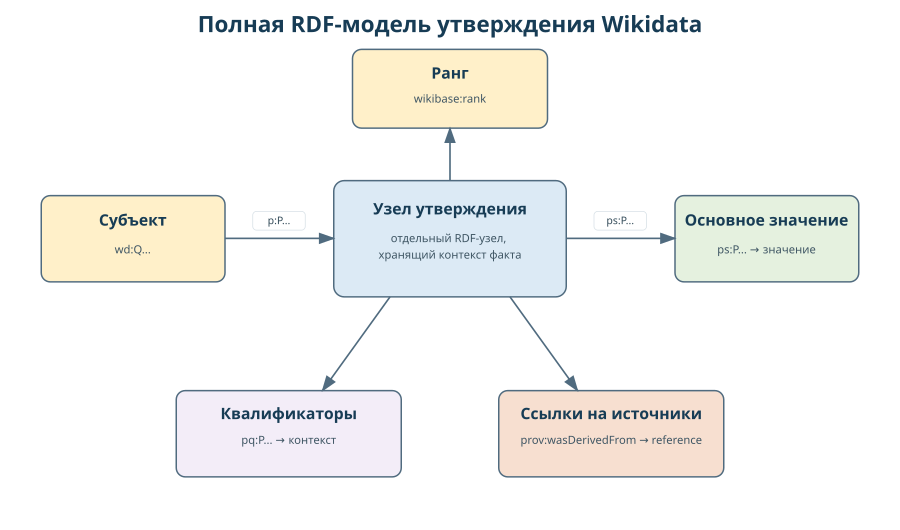

In [5]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="900" height="530" viewBox="0 0 1200 705">
  <rect width="1200" height="705" fill="white"/>
  <defs>
    <marker id="stArrow" markerWidth="11" markerHeight="11" refX="9" refY="3.5" orient="auto">
      <path d="M0,0 L0,7 L10,3.5 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#506b7f;stroke-width:2}
    .title{font:700 21px sans-serif;fill:#173c55;text-anchor:middle}
    .body{font:15px sans-serif;fill:#3e5563;text-anchor:middle}
    .head{font:700 30px sans-serif;fill:#173c55;text-anchor:middle}
    .edge{stroke:#506b7f;stroke-width:2.2;fill:none;marker-end:url(#stArrow)}
    .edgeLabel{font:14px sans-serif;fill:#334b59;text-anchor:middle}
    .labelBg{fill:white;stroke:#d7e0e6;stroke-width:1}
  </style>

  <text x="600" y="42" class="head">Полная RDF-модель утверждения Wikidata</text>

  <rect x="55" y="260" width="245" height="115" rx="12" fill="#fff0c9" class="box"/>
  <text x="177" y="300" class="title">Субъект</text>
  <text x="177" y="337" class="body">wd:Q...</text>

  <rect x="445" y="240" width="310" height="155" rx="14" fill="#dceaf5" class="box"/>
  <text x="600" y="285" class="title">Узел утверждения</text>
  <text x="600" y="322" class="body">
    <tspan x="600" dy="0">отдельный RDF-узел,</tspan>
    <tspan x="600" dy="22">хранящий контекст факта</tspan>
  </text>

  <rect x="900" y="260" width="245" height="115" rx="12" fill="#e5f1df" class="box"/>
  <text x="1022" y="300" class="title">Основное значение</text>
  <text x="1022" y="337" class="body">ps:P... → значение</text>

  <rect x="470" y="65" width="260" height="105" rx="12" fill="#fff0c9" class="box"/>
  <text x="600" y="104" class="title">Ранг</text>
  <text x="600" y="136" class="body">wikibase:rank</text>

  <rect x="235" y="520" width="300" height="115" rx="12" fill="#f3edf8" class="box"/>
  <text x="385" y="558" class="title">Квалификаторы</text>
  <text x="385" y="591" class="body">pq:P... → контекст</text>

  <rect x="665" y="520" width="300" height="115" rx="12" fill="#f7dfd0" class="box"/>
  <text x="815" y="558" class="title">Ссылки на источники</text>
  <text x="815" y="591" class="body">prov:wasDerivedFrom → reference</text>

  <!-- horizontal core -->
  <line x1="300" y1="317" x2="445" y2="317" class="edge"/>
  <rect x="337" y="281" width="70" height="25" rx="5" class="labelBg"/>
  <text x="372" y="298" class="edgeLabel">p:P...</text>

  <line x1="755" y1="317" x2="900" y2="317" class="edge"/>
  <rect x="792" y="281" width="70" height="25" rx="5" class="labelBg"/>
  <text x="827" y="298" class="edgeLabel">ps:P...</text>

  <!-- context branches -->
  <line x1="600" y1="240" x2="600" y2="170" class="edge"/>
  <line x1="520" y1="395" x2="430" y2="520" class="edge"/>
  <line x1="680" y1="395" x2="770" y2="520" class="edge"/>
</svg>
"""

display(SVG(svg))


# Классы и экземпляры: `P31` и `P279`

Свойство **экземпляр класса (`instance of`, `P31`)** связывает конкретную сущность с классом, тогда как **подкласс (`subclass of`, `P279`)** связывает более частный класс с более общим, поэтому эти свойства нельзя использовать как взаимозаменяемые.

Условно отношение можно представить так:

$$
P31(x,C)\land P279(C,D)\Rightarrow x\in D.
$$

Этот вывод отражает содержательный смысл цепочки, однако публичная точка доступа SPARQL не обязана автоматически выполнять OWL-рассуждение, поэтому иерархию в запросах часто проходят явно с помощью пути `wdt:P31/wdt:P279*`.

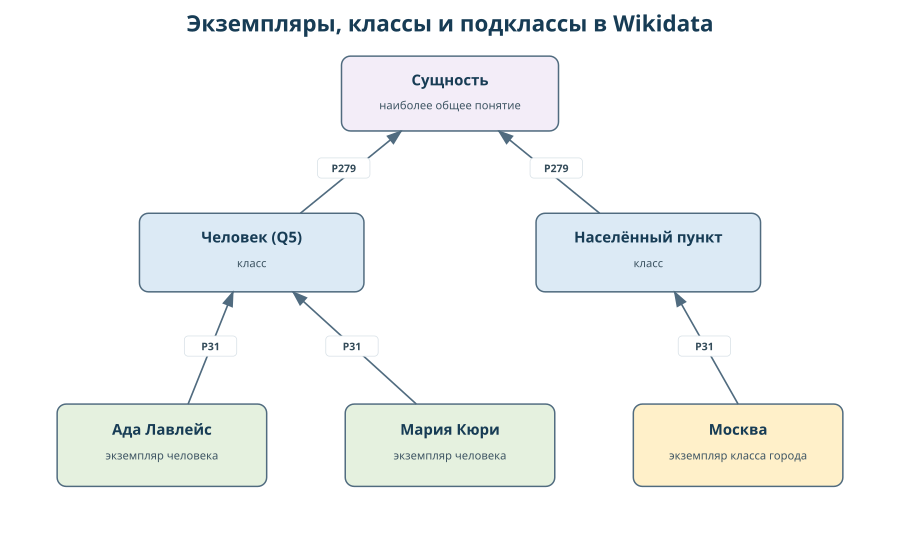

In [6]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="900" height="550" viewBox="0 0 1200 735">
  <rect width="1200" height="735" fill="white"/>
  <defs>
    <marker id="clArrow" markerWidth="11" markerHeight="11" refX="9" refY="3.5" orient="auto">
      <path d="M0,0 L0,7 L10,3.5 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#506b7f;stroke-width:2}
    .title{font:700 20px sans-serif;fill:#173c55;text-anchor:middle}
    .body{font:15px sans-serif;fill:#3e5563;text-anchor:middle}
    .head{font:700 30px sans-serif;fill:#173c55;text-anchor:middle}
    .edge{stroke:#506b7f;stroke-width:2.2;fill:none;marker-end:url(#clArrow)}
    .label{font:700 14px sans-serif;fill:#334b59;text-anchor:middle}
    .labelBg{fill:white;stroke:#d7e0e6;stroke-width:1}
  </style>

  <text x="600" y="42" class="head">Экземпляры, классы и подклассы в Wikidata</text>

  <rect x="455" y="75" width="290" height="100" rx="12" fill="#f3edf8" class="box"/>
  <text x="600" y="114" class="title">Сущность</text>
  <text x="600" y="146" class="body">наиболее общее понятие</text>

  <rect x="185" y="285" width="300" height="105" rx="12" fill="#dceaf5" class="box"/>
  <text x="335" y="324" class="title">Человек (Q5)</text>
  <text x="335" y="357" class="body">класс</text>

  <rect x="715" y="285" width="300" height="105" rx="12" fill="#dceaf5" class="box"/>
  <text x="865" y="324" class="title">Населённый пункт</text>
  <text x="865" y="357" class="body">класс</text>

  <rect x="75" y="540" width="280" height="110" rx="12" fill="#e5f1df" class="box"/>
  <text x="215" y="581" class="title">Ада Лавлейс</text>
  <text x="215" y="614" class="body">экземпляр человека</text>

  <rect x="460" y="540" width="280" height="110" rx="12" fill="#e5f1df" class="box"/>
  <text x="600" y="581" class="title">Мария Кюри</text>
  <text x="600" y="614" class="body">экземпляр человека</text>

  <rect x="845" y="540" width="280" height="110" rx="12" fill="#fff0c9" class="box"/>
  <text x="985" y="581" class="title">Москва</text>
  <text x="985" y="614" class="body">экземпляр класса города</text>

  <!-- P279: class -> superclass, arrows touch borders -->
  <line x1="400" y1="285" x2="535" y2="175" class="edge"/>
  <rect x="423" y="211" width="70" height="27" rx="5" class="labelBg"/>
  <text x="458" y="230" class="label">P279</text>

  <line x1="800" y1="285" x2="665" y2="175" class="edge"/>
  <rect x="707" y="211" width="70" height="27" rx="5" class="labelBg"/>
  <text x="742" y="230" class="label">P279</text>

  <!-- P31: instances -> classes -->
  <line x1="250" y1="540" x2="310" y2="390" class="edge"/>
  <rect x="245" y="449" width="70" height="27" rx="5" class="labelBg"/>
  <text x="280" y="468" class="label">P31</text>

  <line x1="555" y1="540" x2="390" y2="390" class="edge"/>
  <rect x="434" y="449" width="70" height="27" rx="5" class="labelBg"/>
  <text x="469" y="468" class="label">P31</text>

  <line x1="985" y1="540" x2="900" y2="390" class="edge"/>
  <rect x="905" y="449" width="70" height="27" rx="5" class="labelBg"/>
  <text x="940" y="468" class="label">P31</text>
</svg>
"""

display(SVG(svg))


*Схема подчёркивает направление связей: конкретный объект является экземпляром класса через `P31`, а класс связывается с более общим классом через `P279`.*


### Онтологическая структура  Wikidata

В Wikidata нет единственной полностью централизованной и заранее завершённой OWL-онтологии. 

Онтологическая структура возникает из:
- элементов-классов;
- отношений P31 и P279;
- свойств и их метаданных;
- ограничений свойств;
- соглашений проектов и сообществ;
- шаблонов моделирования отдельных предметных областей.

Такой подход обеспечивает гибкость и масштабируемость, но допускает неоднородность. Один объект может быть классифицирован слишком общо, иметь несколько конкурирующих типов или следовать локальному соглашению конкретного сообщества.


### Сокращённое и полное RDF-представления

В RDF-модели Wikidata префикс `wd:` обозначает сущности как RDF-ресурсы, а для простого отбора используется **сокращённое RDF-представление (truthy representation)** - слой прямых троек, в котором предикат `wdt:` ведёт к значениям утверждений лучшего ранга. 

```turtle
wd:Q649 wdt:P17 wd:Q159 .
```

Указанное представление удобно, когда требуется быстро получить основное значение, однако квалификаторы и ссылки на источники в нём не сохраняются, поэтому при необходимости контекста используется **узел утверждения (statement node)** -служебный RDF-узел, который связывает исходную сущность с основным значением, квалификаторами, ссылками на источники и рангом:

```sparql
wd:Q649 p:P1082 ?statement .
?statement ps:P1082 ?population ;
           pq:P585 ?date ;
           wikibase:rank ?rank ;
           prov:wasDerivedFrom ?reference .
```


### Основные пространства имён

Чтобы читать сокращённое и полное RDF-представления, необходимо различать пространства имён, поскольку они показывают, относится ли связь к самой сущности, основному значению, квалификатору или ссылке на источник.

| Префикс | Смысл |
|---|---|
| `wd:` | элементы и свойства как сущности |
| `wdt:` | прямое значение утверждения из сокращённого представления (truthy) |
| `p:` | связь сущности с узлом полного утверждения |
| `ps:` | основное простое значение полного утверждения |
| `psv:` | узел полного значения с единицей, точностью и другими деталями |
| `pq:` | простое значение квалификатора |
| `pqv:` | полное значение квалификатора |
| `pr:` | простое значение свойства ссылки |
| `prov:` | связь утверждения с узлом источника |
| `wikibase:` | служебная онтология Wikibase |


# Как формируется DBpedia

DBpedia создаёт RDF-граф путём автоматического извлечения структурированной информации из проектов Wikimedia, причём **экстрактор (extractor)** представляет собой программный компонент, который читает определённый тип разметки страницы, а **сопоставление (mapping)** связывает поля исходных шаблонов с классами и свойствами онтологии DBpedia.

Упрощённый процесс можно представить как последовательность «страницы и инфобоксы → экстракторы → сопоставление с онтологией → RDF-граф → публикация через связанные данные (Linked Data) и SPARQL».

Основные пространства имён DBpedia:

```text
dbr:  ресурсы DBpedia
dbo:  классы и свойства онтологии DBpedia
dbp:  свойства, непосредственно связанные с полями исходных шаблонов
```

Для переносимых запросов свойства `dbo:` обычно предпочтительнее `dbp:`, поскольку они проходят сопоставление с общей онтологией, однако полного соответствия между свойством DBpedia и PID Wikidata ожидать нельзя.

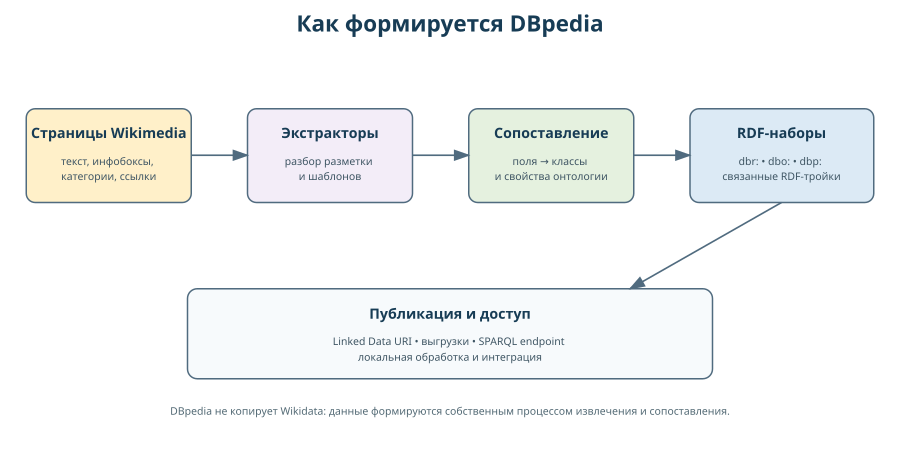

In [7]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="900" height="450" viewBox="0 0 1200 600">
  <rect width="1200" height="600" fill="white"/>
  <defs>
    <marker id="dbArrow" markerWidth="11" markerHeight="11" refX="9" refY="3.5" orient="auto">
      <path d="M0,0 L0,7 L10,3.5 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#506b7f;stroke-width:2}
    .title{font:700 19px sans-serif;fill:#173c55;text-anchor:middle}
    .body{font:14px sans-serif;fill:#3e5563;text-anchor:middle}
    .head{font:700 30px sans-serif;fill:#173c55;text-anchor:middle}
    .edge{stroke:#506b7f;stroke-width:2.2;fill:none;marker-end:url(#dbArrow)}
    .note{font:14px sans-serif;fill:#526974;text-anchor:middle}
  </style>

  <text x="600" y="42" class="head">Как формируется DBpedia</text>

  <rect x="35" y="145" width="220" height="125" rx="12" fill="#fff0c9" class="box"/>
  <text x="145" y="184" class="title">Страницы Wikimedia</text>
  <text x="145" y="220" class="body">
    <tspan x="145" dy="0">текст, инфобоксы,</tspan>
    <tspan x="145" dy="20">категории, ссылки</tspan>
  </text>

  <rect x="330" y="145" width="220" height="125" rx="12" fill="#f3edf8" class="box"/>
  <text x="440" y="184" class="title">Экстракторы</text>
  <text x="440" y="220" class="body">
    <tspan x="440" dy="0">разбор разметки</tspan>
    <tspan x="440" dy="20">и шаблонов</tspan>
  </text>

  <rect x="625" y="145" width="220" height="125" rx="12" fill="#e5f1df" class="box"/>
  <text x="735" y="184" class="title">Сопоставление</text>
  <text x="735" y="220" class="body">
    <tspan x="735" dy="0">поля → классы</tspan>
    <tspan x="735" dy="20">и свойства онтологии</tspan>
  </text>

  <rect x="920" y="145" width="245" height="125" rx="12" fill="#dceaf5" class="box"/>
  <text x="1042" y="184" class="title">RDF-наборы</text>
  <text x="1042" y="220" class="body">
    <tspan x="1042" dy="0">dbr: • dbo: • dbp:</tspan>
    <tspan x="1042" dy="20">связанные RDF-тройки</tspan>
  </text>

  <line x1="255" y1="207" x2="330" y2="207" class="edge"/>
  <line x1="550" y1="207" x2="625" y2="207" class="edge"/>
  <line x1="845" y1="207" x2="920" y2="207" class="edge"/>

  <rect x="250" y="385" width="700" height="120" rx="13" fill="#f7fafc" class="box"/>
  <text x="600" y="425" class="title">Публикация и доступ</text>
  <text x="600" y="460" class="body">
    <tspan x="600" dy="0">Linked Data URI • выгрузки • SPARQL endpoint</tspan>
    <tspan x="600" dy="21">локальная обработка и интеграция</tspan>
  </text>

  <line x1="1042" y1="270" x2="840" y2="385" class="edge"/>

  <text x="600" y="553" class="note">
    DBpedia не копирует Wikidata: данные формируются собственным процессом извлечения и сопоставления.
  </text>
</svg>
"""

display(SVG(svg))


*Схема показывает последовательное преобразование структурированных частей страниц Wikimedia в RDF-граф и последующую публикацию данных через стандартные интерфейсы доступа.*


# Сравнение Wikipedia, Wikidata и DBpedia

| Критерий | Wikipedia | Wikidata | DBpedia |
|---|---|---|---|
| Основная единица | статья | элемент, свойство, утверждение | RDF-ресурс и RDF-тройка |
| Идентификатор | URL страницы | QID и PID | IRI ресурса |
| Представление смысла | связный текст, разделы, таблицы | формальные свойства и значения | RDF и онтология DBpedia |
| Контекст факта | текст и библиографические ссылки | квалификаторы, ссылки на источники и ранг | граф, онтология и происхождение извлечения |
| Многоязычность | отдельные языковые разделы | метки и описания одной сущности | языковые ресурсы и литералы |
| Машинный доступ | программный интерфейс (API), HTML и выгрузки (`dumps`) | программный интерфейс (API), JSON, RDF, SPARQL и пакетные выгрузки данных | связанные данные (Linked Data), SPARQL и пакетные выгрузки данных |
| Сильная сторона | объяснение и содержательный контекст | структурированные утверждения с устойчивыми идентификаторами | стандартный RDF-доступ к извлечённым данным |
| Основное ограничение | факты трудно унифицировать автоматически | моделирование неоднородно, а данные могут быть неполными | результат зависит от правил извлечения и сопоставления |

Поэтому три источника следует рассматривать как взаимодополняющие: Wikipedia помогает понять контекст, Wikidata даёт структурированные утверждения и идентификаторы, а DBpedia позволяет работать с RDF-графом, построенным на основе структурированных частей Wikimedia.

# Показатели качества данных

Пусть $A$ обозначает заранее выбранный набор ожидаемых признаков для класса сущностей, а $A_x$ обозначает признаки, найденные у элемента $x$, тогда **условная полнота** вычисляется как

$$
C(x)=\frac{|A_x\cap A|}{|A|}.
$$

Пусть $S$ представляет множество выбранных утверждений, а $S_{ref}$ представляет утверждения, имеющие хотя бы одну ссылку на источник, тогда **доля утверждений со ссылками на источники** вычисляется как

$$
R_{ref}(x)=\frac{|S_{ref}|}{|S|}.
$$

Оба показателя являются диагностическими, поскольку зависят от заранее выбранных признаков и не заменяют проверку содержания, даты и качества источника.

# Алгоритм анализа сущности в универсальных базах знаний

Когда модели источников и показатели качества рассмотрены, последовательность анализа можно свести к общему алгоритму, который далее применяется в демонстрации Москвы.

**Вход:** название или исходный идентификатор сущности.

**Выход:** аналитическая карточка с идентификаторами, типами, ключевыми утверждениями и оценкой качества.

1. Сформулировать, какой объект требуется найти, и выписать различающие признаки.
2. Найти страницу Wikipedia и элемент Wikidata, проверить описание и ссылки на страницы проектов Wikimedia (sitelinks).
3. Зафиксировать QID, метки и псевдонимы.
4. Найти связь экземпляра с классом (`instance of`, `P31`) и при необходимости пройти цепочку связей подкласса с надклассом (`subclass of`, `P279`).
5. Выбрать 5–10 предметно значимых свойств.
6. Для изменяющихся значений проверить квалификаторы времени.
7. Для ключевых утверждений проверить ссылки и ранг.
8. Найти внешние идентификаторы.
9. Открыть соответствующий ресурс DBpedia и сопоставить классы и свойства.
10. Зафиксировать расхождения: отсутствующее значение, иной тип, устаревшая дата, другое представление.
11. Сформулировать вывод о пригодности каждого источника для выбранной задачи.

**Псевдокод алгоритма**

```text
function analyzeEntity(name):
    candidates := searchWikidata(name)
    entity := disambiguate(candidates)
    card.id := entity.QID
    card.labels := entity.labels
    card.types := getStatements(entity, P31)
    card.facts := selectDomainFacts(entity)
    for fact in card.facts:
        fact.qualifiers := readQualifiers(fact)
        fact.references := readReferences(fact)
        fact.rank := readRank(fact)
    card.externalIds := getExternalIdentifiers(entity)
    card.dbpedia := compareWithDBpedia(entity)
    return assessQuality(card)
```

# Пример - город Москва (`Q649`)

В ходе демонстрации создаются локальные файлы

```text
demo_moscow/Q649.json
demo_moscow/Q649.ttl
demo_moscow/Q183342.json
demo_moscow/Q183342.ttl
demo_moscow/moscow_profile.ttl
```

**Служебный маршрут данных сущности `Special:EntityData`** — это механизм Wikibase, позволяющий получить конкретный элемент в машиночитаемом формате, в том числе JSON и Turtle.

### Идентификация сущности

Анализ начинается с проверки того, что найден именно нужный объект, поскольку совпадение названия само по себе не гарантирует правильный выбор.

| Поле | Значение в демонстрации | Зачем проверять |
|---|---|---|
| Название | Москва | известное для человека понятие |
| QID | `Q649` | устойчивый идентификатор элемента |
| Английская метка | Moscow | используется при сопоставлении с англоязычными ресурсами |
| Описание | столица России | помогает отличить одноимённые или близкие элементы |
| Ссылки на проекты Wikimedia (`sitelinks`) | `ruwiki`, `enwiki` | связывают элемент Wikidata со статьями Wikipedia |

Поскольку QID является устойчивым идентификатором, после проверки описания и ссылок на проекты именно `Q649`, а не текстовая метка «Москва», используется во всех последующих шагах.

### Набор свойств для анализа

В примере рассмотрен небольшой набор свойств, который охватывает разные типы значений и позволяет показать как статические, так и изменяющиеся сведения.

| Содержательный вопрос | PID | Что ожидается увидеть |
|---|---|---|
| Как классифицирован объект? | `P31` | ссылки на классы |
| К какой стране относится объект? | `P17` | ссылка на `Q159` |
| Где находится объект? | `P625` | географические координаты |
| Как представлено население во времени? | `P1082` | количественное значение (`Quantity`) и квалификатор `P585` |
| Какой указан официальный сайт? | `P856` | URL |
| Есть ли внешний географический идентификатор? | `P1566` | идентификатор GeoNames |


### Подготовка локальных файлов

Служебный маршрут `Special:EntityData` позволяет получить один элемент в нескольких форматах, поэтому для города Москвы используются JSON и Turtle:

```text
https://www.wikidata.org/wiki/Special:EntityData/Q649.json
https://www.wikidata.org/wiki/Special:EntityData/Q649.ttl
```

JSON нужен для чтения нативной структуры Wikibase, где поля `claims`, `qualifiers` и `references` соответствуют утверждениям, квалификаторам и ссылкам на источники, а поле `lastrevid` хранит идентификатор **ревизии (revision)** - конкретной версии записи элемента.

Turtle, в свою очередь, сразу представляет тот же объект как RDF-граф, который можно загрузить в RDFLib и анализировать локальными SPARQL-запросами.

Следующая ячейка содержит компактный резервный "образ" для Москвы и выбранного класса, поэтому при наличии сети ноутбук работает с официальным экспортом, а при её отсутствии остаётся воспроизводимым.

In [8]:
MOSCOW_FALLBACK_JSON = {
  "entities": {
    "Q649": {
      "pageid": 649,
      "ns": 0,
      "title": "Q649",
      "lastrevid": 0,
      "modified": "2026-09-21T00:00:00Z",
      "type": "item",
      "id": "Q649",
      "labels": {
        "ru": {
          "language": "ru",
          "value": "Москва"
        },
        "en": {
          "language": "en",
          "value": "Moscow"
        }
      },
      "descriptions": {
        "ru": {
          "language": "ru",
          "value": "столица России"
        },
        "en": {
          "language": "en",
          "value": "capital and most populous city of Russia"
        }
      },
      "aliases": {
        "en": [
          {
            "language": "en",
            "value": "Moskva"
          }
        ]
      },
      "claims": {
        "P31": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P31",
              "datatype": "wikibase-item",
              "datavalue": {
                "value": {
                  "entity-type": "item",
                  "numeric-id": 183342,
                  "id": "Q183342"
                },
                "type": "wikibase-entityid"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {},
            "references": []
          }
        ],
        "P17": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P17",
              "datatype": "wikibase-item",
              "datavalue": {
                "value": {
                  "entity-type": "item",
                  "numeric-id": 159,
                  "id": "Q159"
                },
                "type": "wikibase-entityid"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {},
            "references": []
          }
        ],
        "P625": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P625",
              "datatype": "globe-coordinate",
              "datavalue": {
                "value": {
                  "latitude": 55.750556,
                  "longitude": 37.6175,
                  "altitude": None,
                  "precision": 0.0001,
                  "globe": "http://www.wikidata.org/entity/Q2"
                },
                "type": "globecoordinate"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {},
            "references": []
          }
        ],
        "P856": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P856",
              "datatype": "url",
              "datavalue": {
                "value": "https://www.mos.ru/",
                "type": "string"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {},
            "references": []
          }
        ],
        "P1566": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P1566",
              "datatype": "external-id",
              "datavalue": {
                "value": "524894",
                "type": "string"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {},
            "references": []
          }
        ],
        "P1082": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P1082",
              "datatype": "quantity",
              "datavalue": {
                "value": {
                  "amount": "+13274285",
                  "unit": "1",
                  "upperBound": None,
                  "lowerBound": None
                },
                "type": "quantity"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {
              "P585": [
                {
                  "snaktype": "value",
                  "property": "P585",
                  "datatype": "time",
                  "datavalue": {
                    "value": {
                      "time": "+2025-01-01T00:00:00Z",
                      "timezone": 0,
                      "before": 0,
                      "after": 0,
                      "precision": 11,
                      "calendarmodel": "http://www.wikidata.org/entity/Q1985727"
                    },
                    "type": "time"
                  }
                }
              ]
            },
            "references": [
              {
                "snaks": {
                  "P248": [
                    {
                      "snaktype": "value",
                      "property": "P248",
                      "datatype": "wikibase-item",
                      "datavalue": {
                        "value": {
                          "entity-type": "item",
                          "numeric-id": 133366769,
                          "id": "Q133366769"
                        },
                        "type": "wikibase-entityid"
                      }
                    }
                  ]
                },
                "snaks-order": [
                  "P248"
                ]
              }
            ]
          }
        ]
      },
      "sitelinks": {
        "ruwiki": {
          "site": "ruwiki",
          "title": "Москва",
          "badges": [],
          "url": "https://ru.wikipedia.org/wiki/Москва"
        },
        "enwiki": {
          "site": "enwiki",
          "title": "Moscow",
          "badges": [],
          "url": "https://en.wikipedia.org/wiki/Moscow"
        }
      }
    }
  }
}
MOSCOW_CLASS_FALLBACK_JSON = {
  "entities": {
    "Q183342": {
      "title": "Q183342",
      "lastrevid": 0,
      "type": "item",
      "id": "Q183342",
      "labels": {
        "ru": {
          "language": "ru",
          "value": "город федерального значения России"
        },
        "en": {
          "language": "en",
          "value": "federal city of Russia"
        }
      },
      "descriptions": {
        "en": {
          "language": "en",
          "value": "Russian city which has a status of both an inhabited locality and a constituent federal subject"
        }
      },
      "aliases": {},
      "claims": {
        "P279": [
          {
            "mainsnak": {
              "snaktype": "value",
              "property": "P279",
              "datatype": "wikibase-item",
              "datavalue": {
                "value": {
                  "entity-type": "item",
                  "numeric-id": 43263,
                  "id": "Q43263"
                },
                "type": "wikibase-entityid"
              }
            },
            "type": "statement",
            "rank": "normal",
            "qualifiers": {},
            "references": []
          }
        ]
      },
      "sitelinks": {}
    }
  }
}

MOSCOW_FALLBACK_TTL = r"""@prefix wd: <http://www.wikidata.org/entity/> .
@prefix wdt: <http://www.wikidata.org/prop/direct/> .
@prefix p: <http://www.wikidata.org/prop/> .
@prefix ps: <http://www.wikidata.org/prop/statement/> .
@prefix pq: <http://www.wikidata.org/prop/qualifier/> .
@prefix pr: <http://www.wikidata.org/prop/reference/> .
@prefix wikibase: <http://wikiba.se/ontology#> .
@prefix prov: <http://www.w3.org/ns/prov#> .
@prefix schema: <https://schema.org/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix geo: <http://www.opengis.net/ont/geosparql#> .
@prefix ex: <https://example.org/semtech/demo/> .

wd:Q649 rdfs:label "Москва"@ru, "Moscow"@en ;
    wdt:P31 wd:Q183342 ;
    wdt:P17 wd:Q159 ;
    wdt:P625 "Point(37.6175 55.750556)"^^geo:wktLiteral ;
    wdt:P856 <https://www.mos.ru/> ;
    wdt:P1566 "524894" ;
    wdt:P1082 "13274285"^^xsd:decimal ;
    p:P1082 ex:populationStatement2025 .

ex:populationStatement2025 ps:P1082 "13274285"^^xsd:decimal ;
    pq:P585 "2025-01-01T00:00:00Z"^^xsd:dateTime ;
    wikibase:rank wikibase:NormalRank ;
    prov:wasDerivedFrom ex:populationReference2025 .

ex:populationReference2025 pr:P248 wd:Q133366769 .

<https://ru.wikipedia.org/wiki/Москва> schema:about wd:Q649 ;
    schema:isPartOf <https://ru.wikipedia.org/> .
<https://en.wikipedia.org/wiki/Moscow> schema:about wd:Q649 ;
    schema:isPartOf <https://en.wikipedia.org/> .
"""
MOSCOW_CLASS_FALLBACK_TTL = r"""@prefix wd: <http://www.wikidata.org/entity/> .
@prefix wdt: <http://www.wikidata.org/prop/direct/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
wd:Q183342 rdfs:label "город федерального значения России"@ru, "federal city of Russia"@en ;
    wdt:P279 wd:Q43263 .
"""


In [9]:
def download_to_file(url, path, timeout=25):
    path = Path(path)
    req = Request(url, headers={
        "User-Agent": "SemTechCourseNotebook/1.0 (university educational use)"
    })
    with urlopen(req, timeout=timeout) as response:
        path.write_bytes(response.read())
    return path


def prepare_entity_files(qid, target_dir, fallback_json=None, fallback_ttl=None):
    target_dir = Path(target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)
    result = {}

    specs = {
        "json": (f"https://www.wikidata.org/wiki/Special:EntityData/{qid}.json", target_dir / f"{qid}.json", fallback_json),
        "ttl": (f"https://www.wikidata.org/wiki/Special:EntityData/{qid}.ttl", target_dir / f"{qid}.ttl", fallback_ttl),
    }

    for fmt, (url, path, fallback) in specs.items():
        if path.exists() and path.stat().st_size > 20:
            result[fmt] = {"path": path, "source": "локальный файл уже существовал"}
            continue
        try:
            download_to_file(url, path)
            result[fmt] = {"path": path, "source": "официальный Special:EntityData"}
        except Exception as exc:
            if fallback is None:
                result[fmt] = {"path": path, "source": f"не получен: {type(exc).__name__}"}
            else:
                if fmt == "json":
                    path.write_text(json.dumps(fallback, ensure_ascii=False, indent=2), encoding="utf-8")
                else:
                    path.write_text(fallback, encoding="utf-8")
                result[fmt] = {"path": path, "source": f"встроенный учебный снимок; сеть недоступна ({type(exc).__name__})"}
    return result

DEMO_DIR = Path("demo_moscow")
moscow_files = prepare_entity_files("Q649", DEMO_DIR, MOSCOW_FALLBACK_JSON, MOSCOW_FALLBACK_TTL)
class_files = prepare_entity_files("Q183342", DEMO_DIR, MOSCOW_CLASS_FALLBACK_JSON, MOSCOW_CLASS_FALLBACK_TTL)

rows=[]
for qid, files in [("Q649", moscow_files), ("Q183342", class_files)]:
    for fmt, info in files.items():
        rows.append({"QID":qid,"формат":fmt,"файл":str(info["path"]),"источник":info["source"]})
show_table(rows, ["QID","формат","файл","источник"])


QID,формат,файл,источник
Q649,json,demo_moscow/Q649.json,локальный файл уже существовал
Q649,ttl,demo_moscow/Q649.ttl,локальный файл уже существовал
Q183342,json,demo_moscow/Q183342.json,локальный файл уже существовал
Q183342,ttl,demo_moscow/Q183342.ttl,локальный файл уже существовал


### Проверка подготовленных файлов

После выполнения предыдущей ячейки дальнейший разбор использует только локальные файлы.

In [10]:
def load_wikidata_entity(path, qid):
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    if "entities" not in data or qid not in data["entities"]:
        raise KeyError(f"В файле нет сущности {qid}")
    return data["entities"][qid]

moscow = load_wikidata_entity(moscow_files["json"]["path"], "Q649")
moscow_class = load_wikidata_entity(class_files["json"]["path"], "Q183342")

print("QID:", moscow.get("id"))
print("Последняя ревизия (lastrevid):", moscow.get("lastrevid"))
print("Число групп утверждений (claims):", len(moscow.get("claims", {})))
print("Число ссылок на проекты Wikimedia (sitelinks):", len(moscow.get("sitelinks", {})))

QID: Q649
Последняя ревизия (lastrevid): 0
Число групп утверждений (claims): 6
Число ссылок на проекты Wikimedia (sitelinks): 2


### Чтение JSON

Сначала в JSON проверяются метки в поле `labels`, описания в `descriptions`, псевдонимы в `aliases` и ссылки на проекты Wikimedia в `sitelinks`, поскольку ошибка идентификации сущности должна быть обнаружена до того, как начнётся разбор её утверждений.


In [11]:
rows=[]
for lang in ["ru","en"]:
    label = moscow.get("labels", {}).get(lang, {}).get("value", "-")
    desc = moscow.get("descriptions", {}).get(lang, {}).get("value", "-")
    aliases = [a.get("value") for a in moscow.get("aliases", {}).get(lang, [])[:5]]
    rows.append({"язык":lang,"метка":label,"описание":desc,"aliases":", ".join(aliases) if aliases else "-"})
show_table(rows, ["язык","метка","описание","aliases"])

sitelink_rows=[]
for site in ["ruwiki","enwiki"]:
    s = moscow.get("sitelinks", {}).get(site)
    sitelink_rows.append({"site":site,"title":s.get("title") if s else "-","url":s.get("url") if s else "-"})
show_table(sitelink_rows, ["site","title","url"])


язык,метка,описание,aliases
ru,Москва,столица России,-
en,Moscow,capital and most populous city of Russia,Moskva


site,title,url
ruwiki,Москва,https://ru.wikipedia.org/wiki/Москва
enwiki,Moscow,https://en.wikipedia.org/wiki/Moscow


Когда метка, описание и связанные страницы подтверждают, что выбран элемент Москвы, можно переходить к разделу утверждений (`claims`), где значения извлекаются программно вместе с их типами данных, рангами, квалификаторами и ссылками на источники.

In [12]:
def snak_value(snak):
    if not snak:
        return None
    snak_type = snak.get("snaktype")
    if snak_type != "value":
        return snak_type
    data_value = snak.get("datavalue", {})
    value = data_value.get("value")
    if isinstance(value, dict):
        if "id" in value:
            return value["id"]
        if "amount" in value:
            return value["amount"]
        if "time" in value:
            return value["time"]
        if "latitude" in value and "longitude" in value:
            return f"{value['latitude']}, {value['longitude']}"
    return value


def first_values(entity, pid, limit=10):
    rows = []
    for statement_json in entity.get("claims", {}).get(pid, [])[:limit]:
        main_snak = statement_json.get("mainsnak", {})
        rows.append({
            "PID": pid,
            "значение": snak_value(main_snak),
            "тип данных": main_snak.get("datatype"),
            "ранг": statement_json.get("rank"),
            "квалификаторы": ", ".join(statement_json.get("qualifiers", {}).keys()) or "-",
            "ссылки на источники": len(statement_json.get("references", [])),
        })
    return rows

rows = []
for pid in ["P31", "P17", "P625", "P856", "P1566"]:
    rows.extend(first_values(moscow, pid, limit=5))

show_table(
    rows,
    ["PID", "значение", "тип данных", "ранг", "квалификаторы", "ссылки на источники"]
)

PID,значение,тип данных,ранг,квалификаторы,ссылки на источники
P31,Q183342,wikibase-item,normal,-,0
P17,Q159,wikibase-item,normal,-,0
P625,"55.750556, 37.6175",globe-coordinate,normal,-,0
P856,https://www.mos.ru/,url,normal,-,0
P1566,524894,external-id,normal,-,0


### `P31` и `P279` на основе локальных файлах

В локальном файле Москвы среди значений `P31` находится класс `Q183342`, то есть «город федерального значения России» (`federal city of Russia`), а в отдельном локальном файле этого класса через `P279` можно проверить его связь с более общим классом `Q43263`.

Цепочка имеет вид

```text
Москва (Q649)
  --P31--> город федерального значения России (Q183342)
  --P279--> субъект Российской Федерации (Q43263)
```

Поскольку первый переход связывает конкретный объект с классом, а второй связывает класс с надклассом, перестановка `P31` и `P279` изменила бы смысл модели.

In [13]:
p31_values = [snak_value(c.get("mainsnak")) for c in moscow.get("claims", {}).get("P31", [])]
p279_values = [snak_value(c.get("mainsnak")) for c in moscow_class.get("claims", {}).get("P279", [])]

print("P31 Москвы, первые значения:", p31_values[:10])
print("P279 класса Q183342:", p279_values)

if "Q183342" in p31_values and "Q43263" in p279_values:
    print("Цепочка подтверждена локальными JSON-файлами: Q649 --P31--> Q183342 --P279--> Q43263")
else:
    print("Проверьте текущие файлы: состав P31/P279 в публичной базе мог измениться.")


P31 Москвы, первые значения: ['Q183342']
P279 класса Q183342: ['Q43263']
Цепочка подтверждена локальными JSON-файлами: Q649 --P31--> Q183342 --P279--> Q43263


После относительно устойчивой классификации целесообразно перейти к изменяющемуся во времени факту, например, численности населения, на основе которого хорошо видно, зачем основное значение дополняется квалификатором даты и ссылкой на источник.

### Население как контекстное утверждение

Сведение записи о численности населения к виду

```text
Москва -> численность населения -> N
```

теряет временной контекст и источник данных, тогда как более точная модель имеет вид

```text
Москва -> численность населения -> N
                              -> момент времени -> t
                              -> ссылка на источник -> источник
```

Поэтому для свойства `P1082` извлекаются все доступные утверждения (`statements`) вместе с квалификатором «момент времени» `P585`, рангом и числом ссылок на источники, а не только одно числовое значение.

In [14]:
def qualifier_values(statement_json, pid):
    return [snak_value(s) for s in statement_json.get("qualifiers", {}).get(pid, [])]

def reference_values(statement_json, pid):
    values = []
    for reference_json in statement_json.get("references", []):
        for snak in reference_json.get("snaks", {}).get(pid, []):
            values.append(snak_value(snak))
    return values

population_rows = []
for statement_json in moscow.get("claims", {}).get("P1082", []):
    dates = qualifier_values(statement_json, "P585")
    population_rows.append({
        "население": snak_value(statement_json.get("mainsnak")),
        "момент времени (P585)": dates[0] if dates else "-",
        "ранг": statement_json.get("rank"),
        "число ссылок на источники": len(statement_json.get("references", [])),
        "указано в (P248)": ", ".join(str(x) for x in reference_values(statement_json, "P248")) or "-"
    })

population_rows_sorted = sorted(
    population_rows,
    key=lambda r: r["момент времени (P585)"] if r["момент времени (P585)"] != "-" else "",
    reverse=True
)
show_table(
    population_rows_sorted[:12],
    ["население", "момент времени (P585)", "ранг", "число ссылок на источники", "указано в (P248)"]
)

население,момент времени (P585),ранг,число ссылок на источники,указано в (P248)
+13274285,+2025-01-01T00:00:00Z,normal,1,Q133366769


### Интерпретация полученной строки

Если строка содержит значение численности населения, квалификатор даты `P585` и сведения о ссылке на источник, её следует читать как утверждение о значении, относящемся к конкретному моменту времени и имеющем определённое происхождение, поэтому такое значение нельзя без дополнительной проверки превращать в «вечную» характеристику города.

Корректная формулировка может выглядеть так: в локальном "образе" Wikidata найдено утверждение (`statement`) `P1082`, значение которого относится к указанной дате, имеет зафиксированный ранг и сопровождается указанным числом ссылок на источники.

После того как нативная JSON-структура разобрана, тот же локальный объект открывается как RDF-граф, что позволяет сопоставить прямые предикаты `wdt:` с полной моделью узла утверждения `p:/ps:/pq:/pr:`.

In [15]:
g = Graph()
g.parse(moscow_files["ttl"]["path"], format="turtle")
print("Файл:", moscow_files["ttl"]["path"])
print("Число RDF-троек:", len(g))

rows=[]
for pid in ["P31","P17","P625","P856","P1566","P1082"]:
    pred = WDT[pid]
    vals = list(g.objects(WD["Q649"], pred))
    rows.append({"предикат":f"wdt:{pid}","число значений":len(vals),"первые значения":", ".join(str(v) for v in vals[:4]) or "-"})
show_table(rows, ["предикат","число значений","первые значения"])


Файл: demo_moscow/Q649.ttl
Число RDF-троек: 18


предикат,число значений,первые значения
wdt:P31,1,http://www.wikidata.org/entity/Q183342
wdt:P17,1,http://www.wikidata.org/entity/Q159
wdt:P625,1,Point(37.6175 55.750556)
wdt:P856,1,https://www.mos.ru/
wdt:P1566,1,524894
wdt:P1082,1,13274285


### Что показывает `wdt:`

В сокращённом RDF-представлении субъектом остаётся `wd:Q649`, а предикаты вида `wdt:P...` ведут непосредственно к прямым значениям (`direct values`) утверждений лучшего ранга, поэтому такой слой удобен для простого отбора, но не позволяет увидеть квалификаторы, ссылки на источники и полный набор рангов конкретного свойства.

Именно поэтому `wdt:P1082` отвечает на вопрос о прямом значении населения, тогда как исторический ряд и его контекст требуют перехода к узлу утверждения.

### Локальный SPARQL-запрос к полному утверждению

```sparql
SELECT ?population ?date ?rank ?source
WHERE {
  wd:Q649 p:P1082 ?statement .
  ?statement ps:P1082 ?population ;
             wikibase:rank ?rank .
  OPTIONAL { ?statement pq:P585 ?date . }
  OPTIONAL {
    ?statement prov:wasDerivedFrom ?reference .
    OPTIONAL { ?reference pr:P248 ?source . }
  }
}
```

Запрос показывает те компоненты, которые теряются в сокращённой тройке `wdt:P1082`: дату, ранг и ссылку на источник.

In [16]:
LOCAL_POP_QUERY = PREFIXES + """
SELECT ?population ?date ?rank ?source
WHERE {
  wd:Q649 p:P1082 ?statement .
  ?statement ps:P1082 ?population ;
             wikibase:rank ?rank .
  OPTIONAL { ?statement pq:P585 ?date . }
  OPTIONAL {
    ?statement prov:wasDerivedFrom ?reference .
    OPTIONAL { ?reference pr:P248 ?source . }
  }
}
ORDER BY DESC(?date)
"""

rows = []
for result in g.query(LOCAL_POP_QUERY):
    rows.append({
        "население": result.population,
        "дата": result.date,
        "ранг": result.rank,
        "источник": result.source
    })

show_table(rows[:12], ["население", "дата", "ранг", "источник"])

население,дата,ранг,источник
13274285,2025-01-01T00:00:00+00:00,http://wikiba.se/ontology#NormalRank,http://www.wikidata.org/entity/Q133366769


### Сопоставление JSON и Turtle

Один пользовательский запрос представляется в JSON и RDF разными конструкциями, однако его смысл остаётся сопоставимым:

| Смысл | JSON-модель Wikibase | RDF/Turtle |
|---|---|---|
| субъект | элемент `Q649` | `wd:Q649` |
| свойство населения | ключ `P1082` в разделе `claims` | `p:P1082` или `wdt:P1082` |
| основное значение (`main value`) | `mainsnak.datavalue` | `ps:P1082` |
| квалификатор даты | `qualifiers.P585` | `pq:P585` |
| ссылка на источник (`reference`) | `references[].snaks` | `prov:wasDerivedFrom` и `pr:` |
| ранг (`rank`) | поле `rank` | `wikibase:rank` |

Такое сопоставление показывает, что JSON удобен для чтения нативной структуры Wikibase, тогда как Turtle удобен для интеграции с RDF-инструментами и локального SPARQL-анализа.

После сопоставления двух представлений целесообразно перейти к внешним источникам и проверить, как тот же объект связан со статьями Wikipedia и ресурсом DBpedia.

In [17]:
ru = moscow.get("sitelinks", {}).get("ruwiki")
en = moscow.get("sitelinks", {}).get("enwiki")

en_title = en.get("title") if en else None
DBPEDIA_RESOURCE = (
    f"http://dbpedia.org/resource/{quote(en_title.replace(' ', '_'))}"
    if en_title else None
)

show_table([
    {"источник": "Русская Wikipedia", "идентификатор / URL": ru.get("url") if ru else "-"},
    {"источник": "Английская Wikipedia", "идентификатор / URL": en.get("url") if en else "-"},
    {"источник": "Wikidata", "идентификатор / URL": "https://www.wikidata.org/wiki/Q649"},
    {"источник": "Предполагаемый ресурс DBpedia", "идентификатор / URL": DBPEDIA_RESOURCE or "-"},
], ["источник", "идентификатор / URL"])

источник,идентификатор / URL
Русская Wikipedia,https://ru.wikipedia.org/wiki/Москва
Английская Wikipedia,https://en.wikipedia.org/wiki/Moscow
Wikidata,https://www.wikidata.org/wiki/Q649
Предполагаемый ресурс DBpedia,http://dbpedia.org/resource/Moscow


### Сопоставление фактов с Wikipedia

При сравнении одного факта недостаточно отметить только совпадение или расхождение, поскольку необходимо убедиться, что источники описывают один и тот же аспект объекта и относятся к сопоставимому моменту времени.

| Что сравнивается | Wikipedia | Wikidata | Что требуется проверить |
|---|---|---|---|
| класс объекта | формулировка в начале статьи | `P31` | совпадает ли уровень абстракции |
| координаты | карточка или текст статьи | `P625` | описывается ли одна и та же точка |
| население | значение вместе с годом | `P1082` и `P585` | совпадает ли дата наблюдения |
| официальный сайт | ссылка в статье | `P856` | относится ли URL к текущему официальному ресурсу |

Поскольку Wikipedia может давать более подробное словесное объяснение, а Wikidata хранит нормализованное значение, различие между ними не следует автоматически считать ошибкой.

### Сопоставление с DBpedia

Для англоязычной статьи `Moscow` предполагаемым ресурсом DBpedia является

```text
http://dbpedia.org/resource/Moscow
```

после чего через публичную точку доступа SPARQL (`SPARQL endpoint`) можно проверить типы `rdf:type`, свойства онтологии `dbo:`, свойства исходных шаблонов `dbp:` и связь тождественности `owl:sameAs`:

```sparql
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX dbo: <http://dbpedia.org/ontology/>
PREFIX dbp: <http://dbpedia.org/property/>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT ?p ?o
WHERE {
  <http://dbpedia.org/resource/Moscow> ?p ?o .
}
LIMIT 100
```

Свойство `dbo:` и PID Wikidata нельзя считать взаимозаменяемыми только из-за похожего названия, поскольку две базы формируются разными процессами и могут по-разному определять границы одного отношения.

Когда исходные файлы прочитаны и три источника сопоставлены, определим показатели, которые помогают увидеть пропуски, но не заменяют содержательную проверку данных.

In [18]:
EXPECTED_MOSCOW = ["P31", "P17", "P625", "P1082", "P856", "P1566"]
found = [pid for pid in EXPECTED_MOSCOW if moscow.get("claims", {}).get(pid)]
completeness = len(found) / len(EXPECTED_MOSCOW)

selected_statements = []
for pid in EXPECTED_MOSCOW:
    selected_statements.extend(moscow.get("claims", {}).get(pid, []))

with_references = sum(1 for s in selected_statements if s.get("references"))
reference_rate = (
    with_references / len(selected_statements)
    if selected_statements else 0
)

show_table([
    {
        "показатель": "Условная полнота",
        "значение": f"{completeness:.2f}",
        "интерпретация": f"найдено {len(found)} из {len(EXPECTED_MOSCOW)} заранее выбранных групп свойств"
    },
    {
        "показатель": "Доля утверждений со ссылками на источники",
        "значение": f"{reference_rate:.2f}",
        "интерпретация": f"{with_references} из {len(selected_statements)} выбранных утверждений имеют ссылки на источники"
    },
], ["показатель", "значение", "интерпретация"])

показатель,значение,интерпретация
Условная полнота,1.00,найдено 6 из 6 заранее выбранных групп свойств
Доля утверждений со ссылками на источники,0.17,1 из 6 выбранных утверждений имеют ссылки на источники


### Интерпретация показателей

Если условная полнота равна единице, это означает только наличие всех признаков из заранее выбранного списка, тогда как наличие ссылки на источник само по себе не доказывает качество источника, а отсутствие ссылки не делает утверждение автоматически ложным.

Поэтому такие показатели разумно сравнивать прежде всего для сущностей одного класса и при одинаковом наборе ожидаемых свойств.

Завершая демонстрацию, важно не только прочитать внешние данные, но и сохранить собственный аналитический профиль, в котором фиксируются исследуемая сущность, выбранные свойства, дата анализа и ревизия исходного элемента.

In [19]:
def make_profile_ttl(qid, entity, selected_properties, out_path):
    out_path = Path(out_path)
    rev = entity.get("lastrevid")
    ts = datetime.now(timezone.utc).isoformat(timespec="seconds")
    props = ", ".join(f"wd:{p}" for p in selected_properties)
    text = f'''@prefix ex: <https://example.org/semtech/profile/> .
@prefix wd: <http://www.wikidata.org/entity/> .
@prefix dct: <http://purl.org/dc/terms/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

ex:analysis-{qid}
    a ex:EntityAnalysis ;
    ex:analysedEntity wd:{qid} ;
    ex:analysedProperty {props} ;
    dct:created "{ts}"^^xsd:dateTime ;
    ex:wikidataRevision "{rev if rev is not None else 'unknown'}" .
'''
    out_path.write_text(text, encoding="utf-8")
    return out_path

PROFILE_PATH = make_profile_ttl(
    "Q649",
    moscow,
    ["P31","P17","P625","P1082","P856","P1566"],
    DEMO_DIR / "moscow_profile.ttl"
)

profile_graph = Graph().parse(PROFILE_PATH, format="turtle")
print("Профиль сохранён:", PROFILE_PATH)
print("Троек в профиле:", len(profile_graph))


Профиль сохранён: demo_moscow/moscow_profile.ttl
Троек в профиле: 10


### Результаты

| Этап | Полученный результат |
|---|---|
| идентификация | подтверждён элемент `Q649` |
| локальные данные | созданы и прочитаны `Q649.json` и `Q649.ttl` |
| классовая цепочка | показано различие `P31` и `P279` на классе `Q183342` |
| JSON-модель | разобраны утверждения (`claims`), квалификаторы, ссылки на источники и ранги |
| RDF | локальный Turtle загружен в RDFLib |
| SPARQL | выполнен локальный запрос к полной модели утверждения |
| сопоставление источников | проверена логика связи с Wikipedia и DBpedia |
| качество | рассчитаны условная полнота и доля утверждений со ссылками на источники |
| собственный результат | сохранён файл `moscow_profile.ttl` |


# Индивидуальная работа по номеру студента

Номер студента $N$ в списке группы определяет тип анализируемой сущности.

Для своего варианта необходимо:

1. получить условие по номеру $N$ и выбрать один конкретный объект указанного класса, у которого существует элемент Wikidata и хотя бы одна статья Wikipedia;
2. найти элемент, проверить метку, описание и ссылки на проекты Wikimedia, после чего зафиксировать QID;
3. выбрать 6–8 содержательно значимых свойств и записать их PID, причём рекомендуемый набор из варианта используется как ориентир, а не как механический список;
4. сохранить локальные файлы `QID.json` и `QID.ttl` через `Special:EntityData`, после чего все дальнейшие действия выполнять по этим файлам;
5. прочитать в JSON метки, описание, псевдонимы, ссылки на проекты Wikimedia и раздел утверждений, а затем зафиксировать `lastrevid`, если он присутствует;
6. построить хотя бы одну цепочку `P31 → P279`, проверив отдельно элемент и его класс;
7. выбрать одно утверждение, в котором есть квалификатор или ссылка на источник, и разобрать основное значение, квалификатор, ссылку на источник и ранг;
8. загрузить локальный Turtle в RDFLib и выполнить один SPARQL-запрос к полной модели утверждения через `p:`, `ps:` и, при наличии соответствующих данных, `pq:` и `pr:`;
9. сравнить не менее двух фактов с Wikipedia и, если соответствующий ресурс существует, проверить представление той же сущности в DBpedia;
10. рассчитать условную полноту по заранее заданному собственному списку ожидаемых признаков и долю выбранных утверждений со ссылками на источники;
11. выполнить дополнительный акцент своего варианта, используя только методы, уже показанные в демонстрации Москвы;
12. сохранить краткий аналитический профиль `profile_QID.ttl` и сформулировать вывод, в котором указать дату получения данных, найденные ограничения и возможные причины расхождений между источниками.

In [20]:
N_STUDENTS = 80

ENTITY_PROFILES = [
    {
        "класс": "человек науки",
        "выбор": "выберите учёного или исследователя, для которого есть русская или английская статья Wikipedia",
        "рекомендуемые PID": "P31, P106, P569, P19, P27, P69",
        "контекст": "найдите утверждение с датой, местом работы, образованием или другой контекстной характеристикой"
    },
    {
        "класс": "писатель или поэт",
        "выбор": "выберите писателя или поэта с отдельным элементом Wikidata и статьёй Wikipedia",
        "рекомендуемые PID": "P31, P106, P569, P19, P27, P800",
        "контекст": "разберите утверждение о деятельности, награде, месте работы или другом факте с контекстом"
    },
    {
        "класс": "композитор или музыкант",
        "выбор": "выберите композитора или музыканта с несколькими структурированными утверждениями",
        "рекомендуемые PID": "P31, P106, P569, P19, P1303, P800",
        "контекст": "разберите одно многозначное или контекстное утверждение"
    },
    {
        "класс": "художник или архитектор",
        "выбор": "выберите художника или архитектора, для которого можно проверить произведения или профессиональную деятельность",
        "рекомендуемые PID": "P31, P106, P569, P19, P27, P800",
        "контекст": "разберите утверждение о произведении, награде, месте работы или периоде деятельности"
    },
    {
        "класс": "университет",
        "выбор": "выберите университет с официальным сайтом и статьёй Wikipedia",
        "рекомендуемые PID": "P31, P17, P131, P571, P856, P625",
        "контекст": "разберите утверждение с датой основания, административной принадлежностью или другим контекстом"
    },
    {
        "класс": "город",
        "выбор": "выберите город, для которого в Wikidata присутствуют координаты и сведения о населении",
        "рекомендуемые PID": "P31, P17, P625, P1082, P856, P1566",
        "контекст": "обязательно разберите P1082 вместе с квалификатором P585, если он присутствует"
    },
    {
        "класс": "государство",
        "выбор": "выберите государство с отдельным элементом Wikidata и статьёй Wikipedia",
        "рекомендуемые PID": "P31, P36, P37, P1082, P625, P297",
        "контекст": "разберите изменяющееся или многозначное утверждение, например население или официальный язык"
    },
    {
        "класс": "фильм",
        "выбор": "выберите фильм, для которого есть статья Wikipedia и внешний идентификатор",
        "рекомендуемые PID": "P31, P57, P577, P136, P364, P345",
        "контекст": "разберите утверждение о дате выпуска, награде, участнике или другом факте с контекстом"
    },
    {
        "класс": "программный продукт или технология",
        "выбор": "выберите программный продукт или технологию с официальным сайтом либо репозиторием",
        "рекомендуемые PID": "P31, P178, P571, P348, P856, P1324",
        "контекст": "разберите утверждение о версии, разработчике, дате появления или другом контекстном факте"
    },
    {
        "класс": "организация",
        "выбор": "выберите организацию, для которой указаны местоположение, дата основания и официальный сайт",
        "рекомендуемые PID": "P31, P17, P131, P571, P159, P856",
        "контекст": "разберите утверждение о руководителе, местоположении, дате или другом факте с контекстом"
    },
]

FOCUSES = [
    ("Различение сущности",
     "Особенно подробно объясните, почему выбран именно этот QID, а не одноимённый или близкий элемент, используя метку, описание и ссылки на проекты Wikimedia."),
    ("Классовая цепочка",
     "Особенно подробно проверьте цепочку P31 → P279 и поясните смысл каждого перехода."),
    ("Квалификатор",
     "Особенно подробно разберите одно утверждение с квалификатором и объясните, какую часть смысла потеряло бы основное значение без этого уточнения."),
    ("Ссылка на источник",
     "Особенно подробно разберите одну ссылку на источник и проверьте, к какому именно утверждению она относится."),
    ("Ранг",
     "Особенно подробно сравните ранги выбранных утверждений одного свойства и объясните, как ранг влияет на сокращённое представление wdt:."),
    ("Сопоставление с Wikipedia",
     "Особенно подробно сравните два факта с Wikipedia, обязательно учитывая дату и уровень детализации."),
    ("Сопоставление с DBpedia",
     "Особенно подробно сопоставьте тип или одно свойство Wikidata с представлением в DBpedia и объясните, почему похожие свойства не обязаны быть полными аналогами."),
    ("Внешний идентификатор и полнота",
     "Особенно подробно проверьте один внешний идентификатор и поясните результаты расчёта условной полноты по собственному списку ожидаемых признаков."),
]

variant_records = []
for i in range(N_STUDENTS):
    entity_profile = ENTITY_PROFILES[i % len(ENTITY_PROFILES)]
    focus_title, focus_task = FOCUSES[(i // len(ENTITY_PROFILES)) % len(FOCUSES)]
    variant_records.append({
        "вариант": i + 1,
        "класс": entity_profile["класс"],
        "как выбрать объект": entity_profile["выбор"],
        "рекомендуемые PID": entity_profile["рекомендуемые PID"],
        "контекстное утверждение": entity_profile["контекст"],
        "индивидуальный акцент": focus_title,
        "что дополнительно пояснить": focus_task,
    })

assert len(variant_records) == 80
assert len(set((r['класс'], r['индивидуальный акцент']) for r in variant_records)) == 80

show_table(
    variant_records,
    [
        "вариант",
        "класс",
        "как выбрать объект",
        "рекомендуемые PID",
        "контекстное утверждение",
        "индивидуальный акцент",
    ]
)

вариант,класс,как выбрать объект,рекомендуемые PID,контекстное утверждение,индивидуальный акцент
1,человек науки,"выберите учёного или исследователя, для которого есть русская или английская статья Wikipedia","P31, P106, P569, P19, P27, P69","найдите утверждение с датой, местом работы, образованием или другой контекстной характеристикой",Различение сущности
2,писатель или поэт,выберите писателя или поэта с отдельным элементом Wikidata и статьёй Wikipedia,"P31, P106, P569, P19, P27, P800","разберите утверждение о деятельности, награде, месте работы или другом факте с контекстом",Различение сущности
3,композитор или музыкант,выберите композитора или музыканта с несколькими структурированными утверждениями,"P31, P106, P569, P19, P1303, P800",разберите одно многозначное или контекстное утверждение,Различение сущности
4,художник или архитектор,"выберите художника или архитектора, для которого можно проверить произведения или профессиональную деятельность","P31, P106, P569, P19, P27, P800","разберите утверждение о произведении, награде, месте работы или периоде деятельности",Различение сущности
5,университет,выберите университет с официальным сайтом и статьёй Wikipedia,"P31, P17, P131, P571, P856, P625","разберите утверждение с датой основания, административной принадлежностью или другим контекстом",Различение сущности
6,город,"выберите город, для которого в Wikidata присутствуют координаты и сведения о населении","P31, P17, P625, P1082, P856, P1566","обязательно разберите P1082 вместе с квалификатором P585, если он присутствует",Различение сущности
7,государство,выберите государство с отдельным элементом Wikidata и статьёй Wikipedia,"P31, P36, P37, P1082, P625, P297","разберите изменяющееся или многозначное утверждение, например население или официальный язык",Различение сущности
8,фильм,"выберите фильм, для которого есть статья Wikipedia и внешний идентификатор","P31, P57, P577, P136, P364, P345","разберите утверждение о дате выпуска, награде, участнике или другом факте с контекстом",Различение сущности
9,программный продукт или технология,выберите программный продукт или технологию с официальным сайтом либо репозиторием,"P31, P178, P571, P348, P856, P1324","разберите утверждение о версии, разработчике, дате появления или другом контекстном факте",Различение сущности
10,организация,"выберите организацию, для которой указаны местоположение, дата основания и официальный сайт","P31, P17, P131, P571, P159, P856","разберите утверждение о руководителе, местоположении, дате или другом факте с контекстом",Различение сущности


### Получение своего варианта

Чтобы получить индивидуальное условие, укажите свой номер в списке группы в следующей ячейке; номер варианта совпадает с номером студента, поэтому выбирать уровень сложности или отдельный тип задания не требуется.

In [21]:
STUDENT_NUMBER = 1  # укажите свой номер в списке группы: от 1 до 80

if not 1 <= STUDENT_NUMBER <= 80:
    raise ValueError("Номер студента должен быть от 1 до 80.")

student_variant = variant_records[STUDENT_NUMBER - 1]

show_table(
    [
        {"поле": "Номер варианта", "задание": student_variant["вариант"]},
        {"поле": "Класс сущности", "задание": student_variant["класс"]},
        {"поле": "Как выбрать объект", "задание": student_variant["как выбрать объект"]},
        {"поле": "Рекомендуемые PID", "задание": student_variant["рекомендуемые PID"]},
        {"поле": "Контекстное утверждение", "задание": student_variant["контекстное утверждение"]},
        {"поле": "Индивидуальный акцент", "задание": student_variant["индивидуальный акцент"]},
        {"поле": "Что дополнительно пояснить", "задание": student_variant["что дополнительно пояснить"]},
    ],
    ["поле", "задание"]
)

поле,задание
Номер варианта,1
Класс сущности,человек науки
Как выбрать объект,"выберите учёного или исследователя, для которого есть русская или английская статья Wikipedia"
Рекомендуемые PID,"P31, P106, P569, P19, P27, P69"
Контекстное утверждение,"найдите утверждение с датой, местом работы, образованием или другой контекстной характеристикой"
Индивидуальный акцент,Различение сущности
Что дополнительно пояснить,"Особенно подробно объясните, почему выбран именно этот QID, а не одноимённый или близкий элемент, используя метку, описание и ссылки на проекты Wikimedia."


### Настройка выбранной сущности

После получения варианта найдите конкретный объект требуемого класса, проверьте его в веб-интерфейсе Wikidata и только затем укажите QID ниже, поскольку дальнейшее автоматическое получение файлов должно выполняться уже для проверенного элемента.

In [22]:
STUDENT_QID = ""  # после проверки элемента укажите QID, например "Q7259"

if STUDENT_QID and not re.fullmatch(r"Q\d+", STUDENT_QID):
    raise ValueError("QID должен иметь вид Q12345.")

if not STUDENT_QID:
    print("Укажите QID выбранной сущности в переменной STUDENT_QID и повторно выполните ячейку.")
else:
    STUDENT_DIR = Path(f"student_{STUDENT_NUMBER}_{STUDENT_QID}")
    student_links = {
        "Wikidata": f"https://www.wikidata.org/wiki/{STUDENT_QID}",
        "JSON": f"https://www.wikidata.org/wiki/Special:EntityData/{STUDENT_QID}.json",
        "Turtle": f"https://www.wikidata.org/wiki/Special:EntityData/{STUDENT_QID}.ttl",
    }
    show_table(
        [{"ресурс": k, "URL": v} for k, v in student_links.items()],
        ["ресурс", "URL"]
    )

Укажите QID выбранной сущности в переменной STUDENT_QID и повторно выполните ячейку.


### Работа с файлами своего варианта

Для индивидуальной части используется тот же механизм, что и в демонстрации Москвы, но без встроенного резервного снимка, поэтому при доступной сети функция автоматически сохраняет JSON и Turtle, а при отсутствии сети студент вручную открывает сформированные ссылки, сохраняет оба файла в папку своего варианта и затем продолжает анализ уже локально.

In [23]:
if STUDENT_QID:
    STUDENT_DIR = Path(f"student_{STUDENT_NUMBER}_{STUDENT_QID}")
    student_files = prepare_entity_files(STUDENT_QID, STUDENT_DIR)
    show_table(
        [
            {"формат": fmt, "файл": str(info["path"]), "статус": info["source"]}
            for fmt, info in student_files.items()
        ],
        ["формат", "файл", "статус"]
    )
else:
    print("Сначала укажите STUDENT_QID в предыдущей ячейке.")

Сначала укажите STUDENT_QID в предыдущей ячейке.
